In [1]:
pip install numpy  pandas matplotlib  seaborn  scikit-learn  scipy statsmodels

In [2]:
pip install ucimlrepo

In [3]:
pip install sklearn_som

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans,DBSCAN
from sklearn.manifold import TSNE
from sklearn_som.som import SOM
from scipy.stats import ttest_ind

In [5]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
eeg_eye_state = fetch_ucirepo(id=264)

# data (as pandas dataframes)
X = eeg_eye_state.data.features
y = eeg_eye_state.data.targets


In [6]:
y.columns=['eye_state'] #rename target

In [7]:
#combine into dataframe
df=pd.concat([X,y],axis=1)

In [8]:
# Assuming your dataframe is named 'df'
rename_map = {
    'AF3': 'antero_frontal_left_3',
    'F7':  'frontal_left_7',
    'F3':  'frontal_left_3',
    'FC5': 'frontocentral_left_5',
    'T7':  'temporal_left_7',
    'P7':  'parietal_left_7',
    'O1':  'occipital_left_1',
    'O2':  'occipital_right_2',
    'P8':  'parietal_right_8',
    'T8':  'temporal_right_8',
    'FC6': 'frontocentral_right_6',
    'F4':  'frontal_right_4',
    'F8':  'frontal_right_8',
    'AF4': 'antero_frontal_right_4'
}

df = df.rename(columns=rename_map)

In [9]:
df.head()

,antero_frontal_left_3,frontal_left_7,frontal_left_3,frontocentral_left_5,temporal_left_7,parietal_left_7,occipital_left_1,occipital_right_2,parietal_right_8,temporal_right_8,frontocentral_right_6,frontal_right_4,frontal_right_8,antero_frontal_right_4,eye_state
0,4329.23,4009.23,4289.23,4148.21,4350.26,4586.15,4096.92,4641.03,4222.05,4238.46,4211.28,4280.51,4635.90,4393.85,0
1,4324.62,4004.62,4293.85,4148.72,4342.05,4586.67,4097.44,4638.97,4210.77,4226.67,4207.69,4279.49,4632.82,4384.10,0
2,4327.69,4006.67,4295.38,4156.41,4336.92,4583.59,4096.92,4630.26,4207.69,4222.05,4206.67,4282.05,4628.72,4389.23,0
3,4328.72,4011.79,4296.41,4155.90,4343.59,4582.56,4097.44,4630.77,4217.44,4235.38,4210.77,4287.69,4632.31,4396.41,0
4,4326.15,4011.79,4292.31,4151.28,4347.69,4586.67,4095.90,4627.69,4210.77,4244.10,4212.82,4288.21,4632.82,4398.46,0


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14980 entries, 0 to 14979
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   antero_frontal_left_3   14980 non-null  float64
 1   frontal_left_7          14980 non-null  float64
 2   frontal_left_3          14980 non-null  float64
 3   frontocentral_left_5    14980 non-null  float64
 4   temporal_left_7         14980 non-null  float64
 5   parietal_left_7         14980 non-null  float64
 6   occipital_left_1        14980 non-null  float64
 7   occipital_right_2       14980 non-null  float64
 8   parietal_right_8        14980 non-null  float64
 9   temporal_right_8        14980 non-null  float64
 10  frontocentral_right_6   14980 non-null  float64
 11  frontal_right_4         14980 non-null  float64
 12  frontal_right_8         14980 non-null  float64
 13  antero_frontal_right_4  14980 non-null  float64
 14  eye_state               14980 non-null

In [11]:
df.isna().sum()

,0
antero_frontal_left_3,0
frontal_left_7,0
frontal_left_3,0
frontocentral_left_5,0
temporal_left_7,0
parietal_left_7,0
occipital_left_1,0
occipital_right_2,0
parietal_right_8,0
temporal_right_8,0


## 1. Exploratory Data Analysis

Boxplots to compare the distribution of each feature across the two eye state classes (closed vs open).
Outlier detection is performed using the interquartile range (IQR) and the cleaned data is re‑visualised to confirm the effect of the cleaning step.

### 1.1 Boxplots

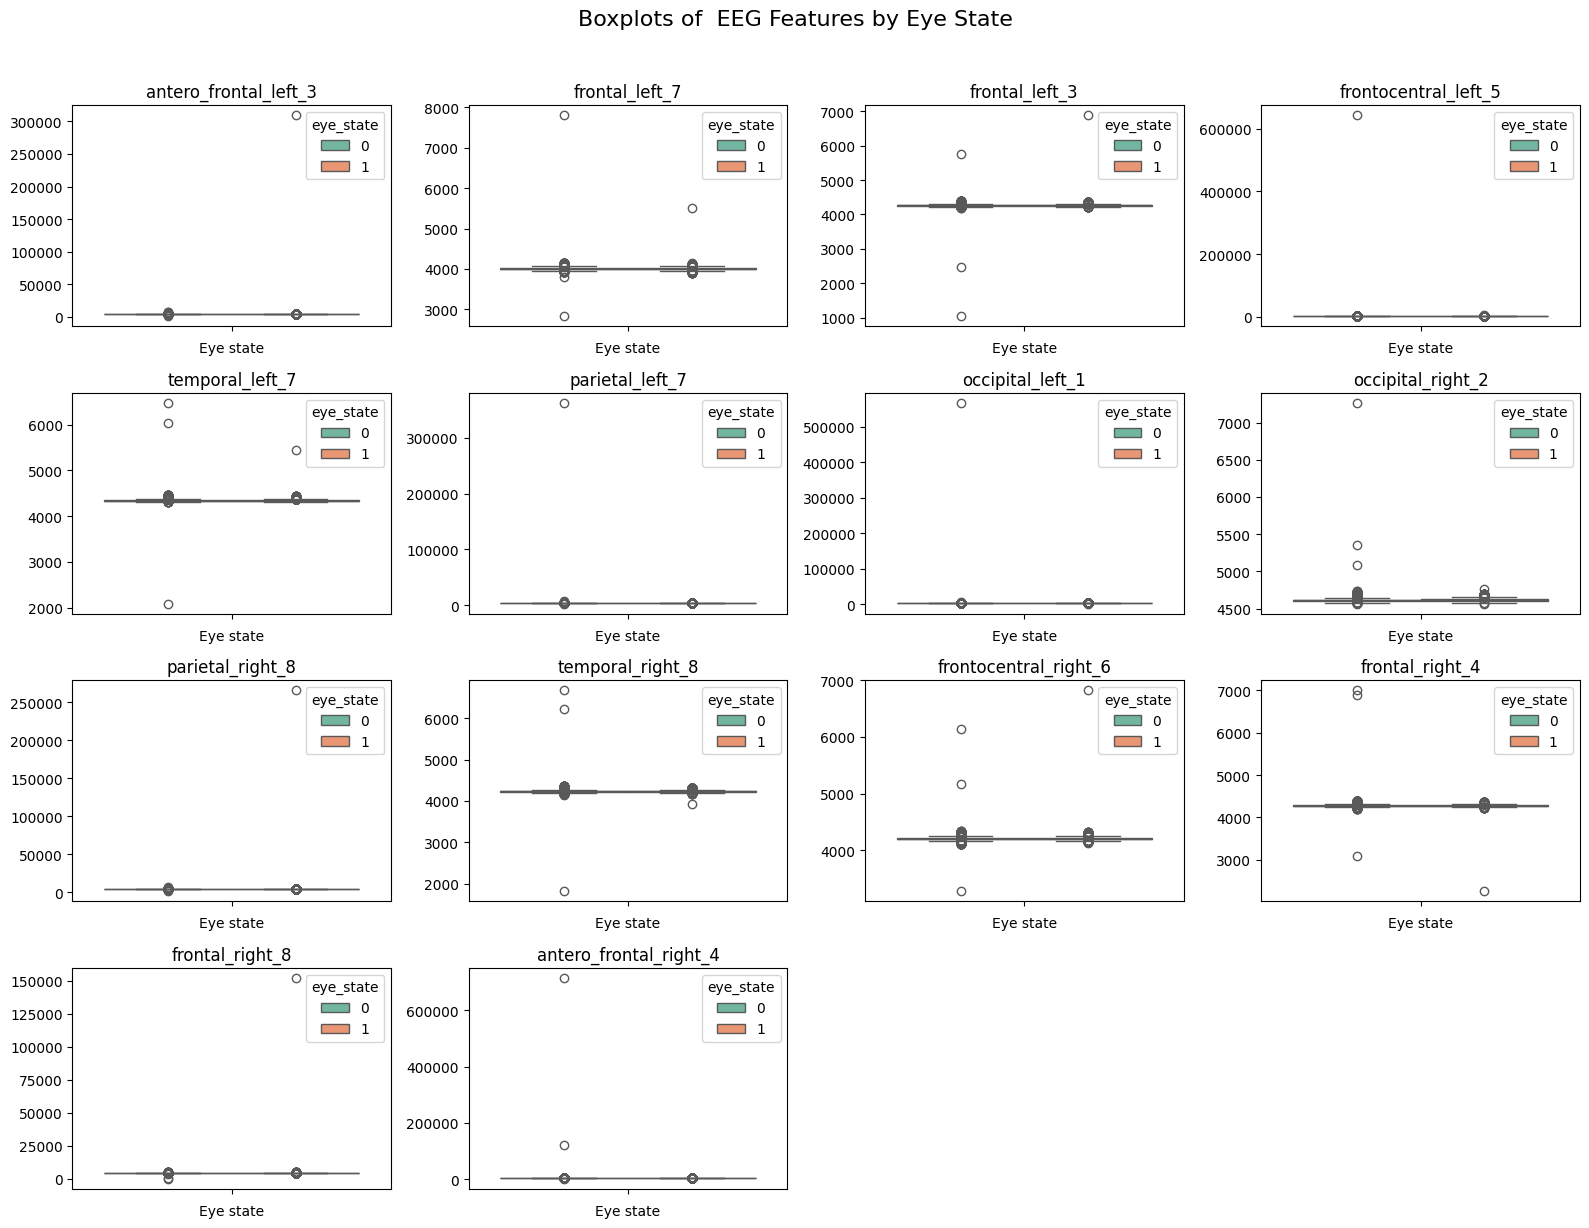

In [12]:
import math

# Define numeric columns excluding the eye_state target
numeric_cols = [c for c in df.columns if c != 'eye_state']
num_features = len(numeric_cols)
cols = 4
rows = math.ceil(num_features / cols)

plt.figure(figsize=(4*cols, 3*rows))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(rows, cols, i)
    sns.boxplot(hue=df['eye_state'], y=df[col], palette='Set2')
    plt.title(col)
    plt.xlabel('Eye state')
    plt.ylabel('')
# Add a common title and adjust layout
plt.suptitle('Boxplots of  EEG Features by Eye State', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

### 1.2 Outlier Detection (IQR Method)

Outliers can skew summary statistics and degrade the performance of downstream algorithms.
Interquartile range (IQR) method to detect outliers for each feature. The number of detected outliers is summarised in a bar chart. After detection, outliers are clipped to the upper and lower bounds.

In [13]:
# Summary statistics before outlier removal
df.describe()

,antero_frontal_left_3,frontal_left_7,frontal_left_3,frontocentral_left_5,temporal_left_7,parietal_left_7,occipital_left_1,occipital_right_2,parietal_right_8,temporal_right_8,frontocentral_right_6,frontal_right_4,frontal_right_8,antero_frontal_right_4,eye_state
count,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000
mean,4321.917777,4009.767694,4264.022433,4164.946326,4341.741075,4644.022379,4110.400160,4616.056904,4218.826610,4231.316200,4202.456900,4279.232774,4615.205336,4416.435832,0.448798
std,2492.072174,45.941672,44.428052,5216.404632,34.738821,2924.789537,4600.926543,29.292603,2136.408523,38.050903,37.785981,41.544312,1208.369958,5891.285043,0.497388
min,1030.770000,2830.770000,1040.000000,2453.330000,2089.740000,2768.210000,2086.150000,4567.180000,1357.950000,1816.410000,3273.330000,2257.950000,86.666700,1366.150000,0.000000
25%,4280.510000,3990.770000,4250.260000,4108.210000,4331.790000,4611.790000,4057.950000,4604.620000,4190.770000,4220.510000,4190.260000,4267.690000,4590.770000,4342.050000,0.000000
50%,4294.360000,4005.640000,4262.560000,4120.510000,4338.970000,4617.950000,4070.260000,4613.330000,4199.490000,4229.230000,4200.510000,4276.920000,4603.080000,4354.870000,0.000000
75%,4311.790000,4023.080000,4270.770000,4132.310000,4347.180000,4626.670000,4083.590000,4624.100000,4209.230000,4239.490000,4211.280000,4287.180000,4617.440000,4372.820000,1.000000
max,309231.000000,7804.620000,6880.510000,642564.000000,6474.360000,362564.000000,567179.000000,7264.100000,265641.000000,6674.360000,6823.080000,7002.560000,152308.000000,715897.000000,1.000000


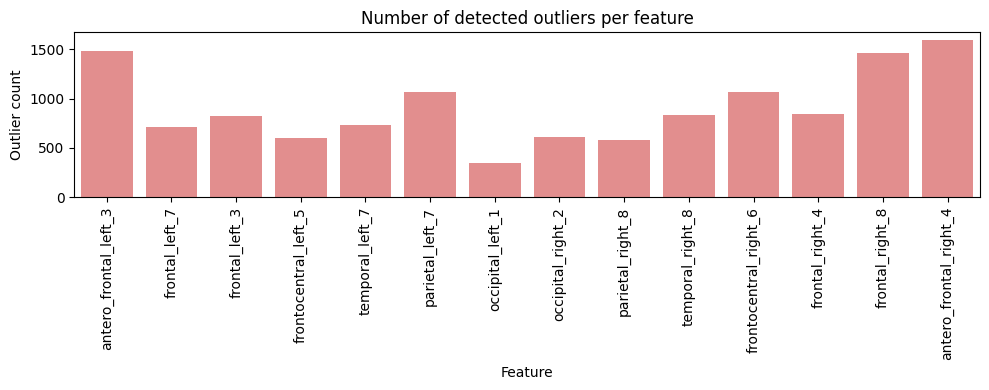

,0
antero_frontal_left_3,1485
frontal_left_7,710
frontal_left_3,825
frontocentral_left_5,601
temporal_left_7,727
parietal_left_7,1065
occipital_left_1,348
occipital_right_2,609
parietal_right_8,584
temporal_right_8,830


In [14]:
# Compute IQR bounds for each feature
numerical_features = df.drop(columns=['eye_state'])
Q1 = numerical_features.quantile(0.25)
Q3 = numerical_features.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers per feature
outlier_mask = (numerical_features < lower_bound) | (numerical_features > upper_bound)
outlier_counts = outlier_mask.sum()

# Visualise how many outliers each feature has
plt.figure(figsize=(10, 4))
sns.barplot(x=outlier_counts.index, y=outlier_counts.values, color='lightcoral')
plt.title('Number of detected outliers per feature')
plt.ylabel('Outlier count')
plt.xlabel('Feature')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Display the raw counts in a table for reference
outlier_counts

In [15]:
# Clip values outside the IQR bounds to reduce the influence of extreme values
numerical_features = numerical_features.clip(lower=lower_bound, axis=1)
numerical_features = numerical_features.clip(upper=upper_bound, axis=1)

# After clipping, recompute the IQR to verify that no values lie outside the bounds
Q1_clean = numerical_features.quantile(0.25)
Q3_clean = numerical_features.quantile(0.75)
IQR_clean = Q3_clean - Q1_clean
lb_clean = Q1_clean - 1.5 * IQR_clean
ub_clean = Q3_clean + 1.5 * IQR_clean
outlier_mask_clean = (numerical_features < lb_clean) | (numerical_features > ub_clean)
print('Total remaining outliers after clipping:', outlier_mask_clean.sum().sum())

Total remaining outliers after clipping: 0


In [16]:
# Inspect the distribution again after clipping
Q1 = numerical_features.quantile(0.25)
Q3 = numerical_features.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outlier_mask = (numerical_features < lower_bound) | (numerical_features > upper_bound)
outlier_mask.sum()

,0
antero_frontal_left_3,0
frontal_left_7,0
frontal_left_3,0
frontocentral_left_5,0
temporal_left_7,0
parietal_left_7,0
occipital_left_1,0
occipital_right_2,0
parietal_right_8,0
temporal_right_8,0


In [17]:
df_cleaned=pd.concat([numerical_features,df['eye_state']],axis=1)

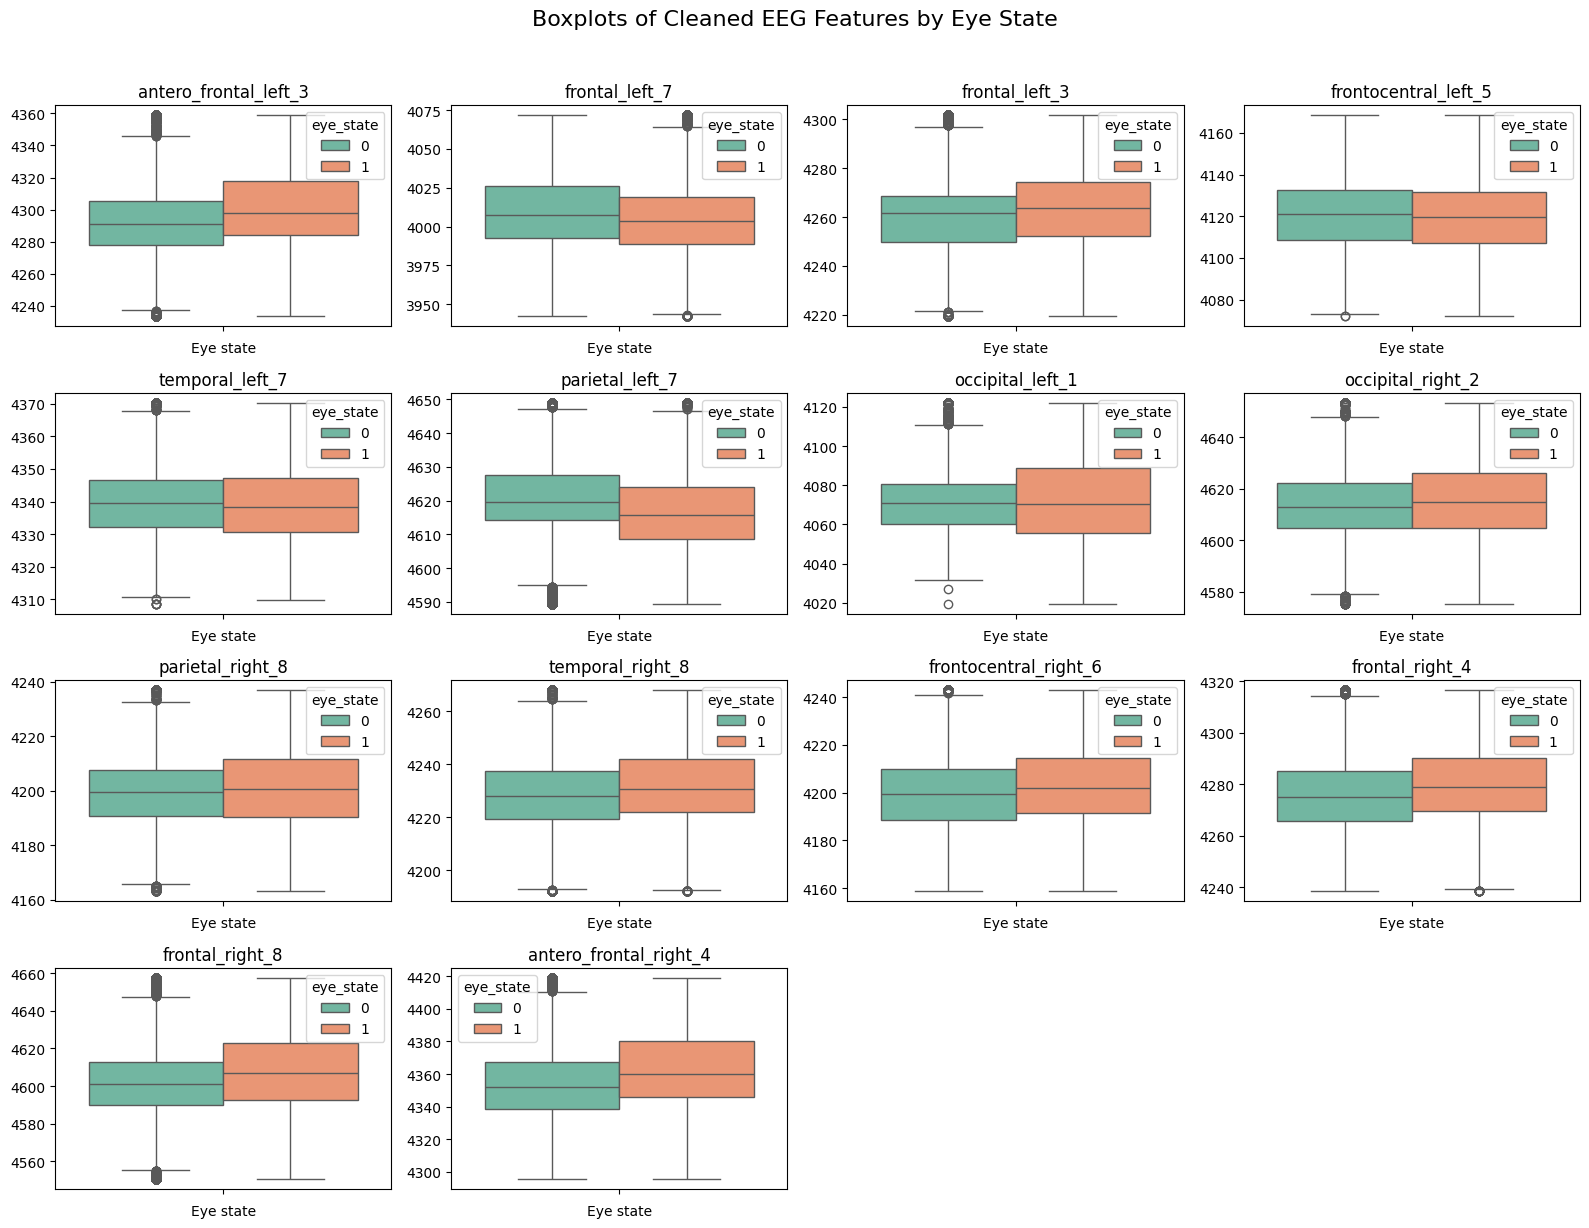

In [18]:
# Boxplots of Cleaned Features
import math

# Define numeric columns excluding the eye_state target
numeric_cols = [c for c in df_cleaned.columns if c != 'eye_state']
num_features = len(numeric_cols)
cols = 4
rows = math.ceil(num_features / cols)

plt.figure(figsize=(4*cols, 3*rows))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(rows, cols, i)
    sns.boxplot(hue=df_cleaned['eye_state'], y=df_cleaned[col], palette='Set2')
    plt.title(col)
    plt.xlabel('Eye state')
    plt.ylabel('')
# Add a common title and adjust layout
plt.suptitle('Boxplots of Cleaned EEG Features by Eye State', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

In [19]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14980 entries, 0 to 14979
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   antero_frontal_left_3   14980 non-null  float64
 1   frontal_left_7          14980 non-null  float64
 2   frontal_left_3          14980 non-null  float64
 3   frontocentral_left_5    14980 non-null  float64
 4   temporal_left_7         14980 non-null  float64
 5   parietal_left_7         14980 non-null  float64
 6   occipital_left_1        14980 non-null  float64
 7   occipital_right_2       14980 non-null  float64
 8   parietal_right_8        14980 non-null  float64
 9   temporal_right_8        14980 non-null  float64
 10  frontocentral_right_6   14980 non-null  float64
 11  frontal_right_4         14980 non-null  float64
 12  frontal_right_8         14980 non-null  float64
 13  antero_frontal_right_4  14980 non-null  float64
 14  eye_state               14980 non-null

## 2. Correlation Analysis
The relationships among the cleaned features and also between each feature and the target label. Understanding these correlations helps identify redundant features and those that are strongly associated with the eye state.

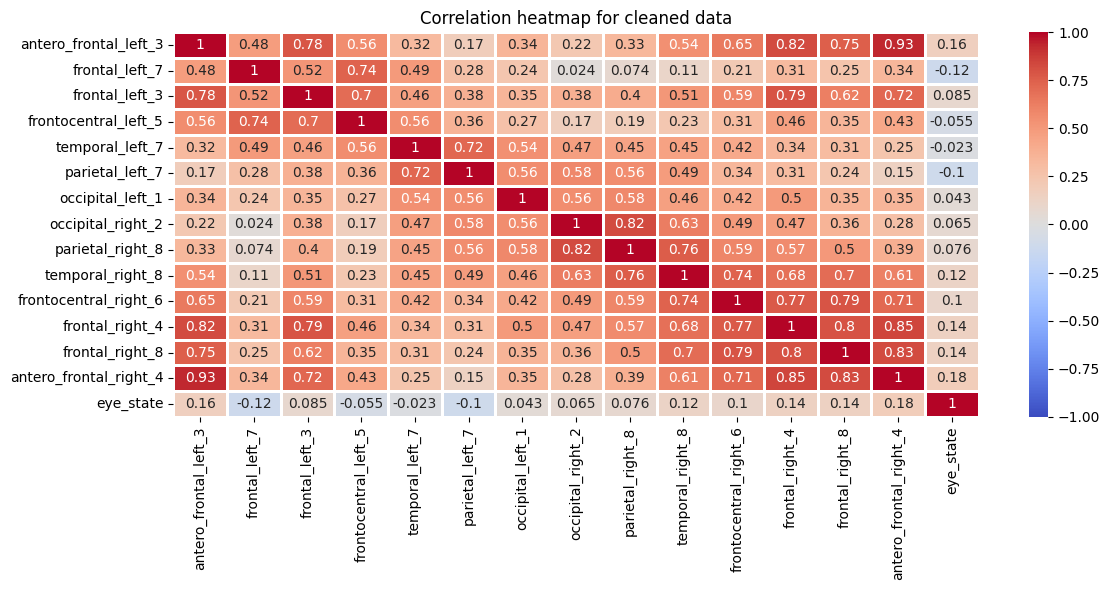

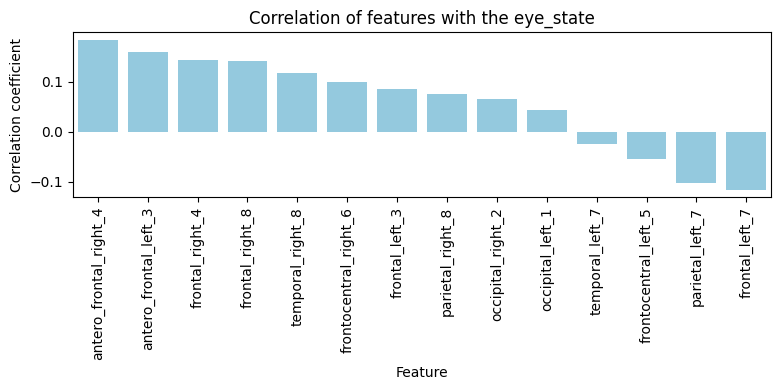

,Correlation with eye_state
antero_frontal_right_4,0.184108
antero_frontal_left_3,0.159809
frontal_right_4,0.144158
frontal_right_8,0.140817
temporal_right_8,0.117417
frontocentral_right_6,0.100599
frontal_left_3,0.085209
parietal_right_8,0.076110
occipital_right_2,0.065426
occipital_left_1,0.043117


In [20]:
# Compute the correlation matrix
corr_matrix = df_cleaned.corr()

# Heatmap showing correlations among all variables
plt.figure(figsize=(12, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=2)
plt.title('Correlation heatmap for cleaned data')
plt.tight_layout()
plt.show()

# Highlight the correlation of each feature with the target
target_corr = corr_matrix['eye_state'].drop('eye_state').sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=target_corr.index, y=target_corr.values, color='skyblue')
plt.title('Correlation of features with the eye_state')
plt.ylabel('Correlation coefficient')
plt.xlabel('Feature')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Display the correlation values as a table
target_corr.to_frame(name='Correlation with eye_state')

In [21]:
# Transpose of the correlation matrix (optional)
df_cleaned.corr().T

,antero_frontal_left_3,frontal_left_7,frontal_left_3,frontocentral_left_5,temporal_left_7,parietal_left_7,occipital_left_1,occipital_right_2,parietal_right_8,temporal_right_8,frontocentral_right_6,frontal_right_4,frontal_right_8,antero_frontal_right_4,eye_state
antero_frontal_left_3,1.000000,0.482822,0.782064,0.558324,0.316832,0.172750,0.344372,0.223545,0.334997,0.539680,0.646727,0.820561,0.754046,0.931671,0.159809
frontal_left_7,0.482822,1.000000,0.520660,0.739178,0.493497,0.280069,0.237494,0.024123,0.074037,0.108524,0.213036,0.313365,0.254180,0.336122,-0.115335
frontal_left_3,0.782064,0.520660,1.000000,0.695699,0.461849,0.375466,0.347602,0.379273,0.404640,0.511440,0.588427,0.789483,0.619086,0.724632,0.085209
frontocentral_left_5,0.558324,0.739178,0.695699,1.000000,0.557149,0.364878,0.273225,0.170398,0.187185,0.231871,0.309936,0.461998,0.349221,0.429489,-0.054928
temporal_left_7,0.316832,0.493497,0.461849,0.557149,1.000000,0.721748,0.544786,0.471208,0.449652,0.453393,0.415712,0.343741,0.311958,0.248724,-0.023221
parietal_left_7,0.172750,0.280069,0.375466,0.364878,0.721748,1.000000,0.559903,0.580911,0.561902,0.485348,0.343514,0.305961,0.237646,0.148354,-0.103114
occipital_left_1,0.344372,0.237494,0.347602,0.273225,0.544786,0.559903,1.000000,0.555433,0.581497,0.464259,0.420318,0.499439,0.351750,0.347693,0.043117
occipital_right_2,0.223545,0.024123,0.379273,0.170398,0.471208,0.580911,0.555433,1.000000,0.820524,0.627709,0.493584,0.471838,0.355473,0.275527,0.065426
parietal_right_8,0.334997,0.074037,0.404640,0.187185,0.449652,0.561902,0.581497,0.820524,1.000000,0.760533,0.593476,0.567050,0.500578,0.388454,0.076110
temporal_right_8,0.539680,0.108524,0.511440,0.231871,0.453393,0.485348,0.464259,0.627709,0.760533,1.000000,0.737253,0.683611,0.695828,0.609737,0.117417


## 3. Feature Scaling and Fisher Distance

The classification algorithms used later are sensitive to the scale of the input features.
Therefore normalise all numeric features (except the label) using z‑scores.
Then compute the Fisher distance of each feature, which measures how well the feature separates the two classes.

### 3.1 Z‑score Normalisation

Standardising the features centres them around zero with unit variance. This step ensures that features with larger numeric ranges do not dominate those with smaller ranges.

In [22]:
# Apply z‑score normalisation to each cleaned feature
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_cleaned.drop(columns=['eye_state']))
df_scaled = pd.DataFrame(scaled_data, columns=df_cleaned.drop(columns=['eye_state']).columns)

# Preview the first few rows of the scaled data
df_scaled.head()

,antero_frontal_left_3,frontal_left_7,frontal_left_3,frontocentral_left_5,temporal_left_7,parietal_left_7,occipital_left_1,occipital_right_2,parietal_right_8,temporal_right_8,frontocentral_right_6,frontal_right_4,frontal_right_8,antero_frontal_right_4
0,1.098253,0.024010,1.574895,1.444123,0.820650,-2.267908,1.287011,1.686400,1.440427,0.504072,0.532557,0.140252,1.266331,1.223164
1,0.934518,-0.147133,1.849421,1.471826,0.148406,-2.267908,1.314170,1.553186,0.685346,-0.227306,0.344161,0.078676,1.141347,0.882066
2,1.043556,-0.071028,1.940336,1.889545,-0.271644,-2.267908,1.287011,0.989934,0.479171,-0.513902,0.290634,0.233220,0.974973,1.061536
3,1.080139,0.119048,2.001540,1.861842,0.274503,-2.267908,1.314170,1.022914,1.131834,0.313008,0.505793,0.573701,1.120652,1.312724
4,0.988860,0.119048,1.757912,1.610885,0.610215,-2.267908,1.233737,0.823739,0.685346,0.853943,0.613373,0.605092,1.141347,1.384442


In [23]:
# Append the target column back to the scaled dataframe
df_scaled = pd.concat([df_scaled, df_cleaned['eye_state'].reset_index(drop=True)], axis=1)

# Inspect the resulting dataframe
df_scaled.head()

,antero_frontal_left_3,frontal_left_7,frontal_left_3,frontocentral_left_5,temporal_left_7,parietal_left_7,occipital_left_1,occipital_right_2,parietal_right_8,temporal_right_8,frontocentral_right_6,frontal_right_4,frontal_right_8,antero_frontal_right_4,eye_state
0,1.098253,0.024010,1.574895,1.444123,0.820650,-2.267908,1.287011,1.686400,1.440427,0.504072,0.532557,0.140252,1.266331,1.223164,0
1,0.934518,-0.147133,1.849421,1.471826,0.148406,-2.267908,1.314170,1.553186,0.685346,-0.227306,0.344161,0.078676,1.141347,0.882066,0
2,1.043556,-0.071028,1.940336,1.889545,-0.271644,-2.267908,1.287011,0.989934,0.479171,-0.513902,0.290634,0.233220,0.974973,1.061536,0
3,1.080139,0.119048,2.001540,1.861842,0.274503,-2.267908,1.314170,1.022914,1.131834,0.313008,0.505793,0.573701,1.120652,1.312724,0
4,0.988860,0.119048,1.757912,1.610885,0.610215,-2.267908,1.233737,0.823739,0.685346,0.853943,0.613373,0.605092,1.141347,1.384442,0


In [24]:
# Define a helper function to compute the Fisher distance.
# The Fisher distance quantifies the separation between the class means relative to the within‑class variance.
# Larger values indicate features that better discriminate between classes.
def calculate_fisher_distance(X, y=df_scaled['eye_state']):
    classes = np.unique(y)
    # Split the data into the two classes
    x0 = X[y == classes[0]]
    x1 = X[y == classes[1]]
    # Compute class means
    mean_closed = np.mean(x0, axis=0)
    mean_open = np.mean(x1, axis=0)
    # Compute class variances
    var_closed = np.var(x0, axis=0)
    var_open = np.var(x1, axis=0)
    # Fisher distance formula
    fisher = (mean_closed - mean_open) ** 2 / (var_closed + var_open)
    return fisher.round(3)

/tmp/ipykernel_3421/713804663.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Feature', y='Fisher Distance', data=fisher_table, palette='viridis')


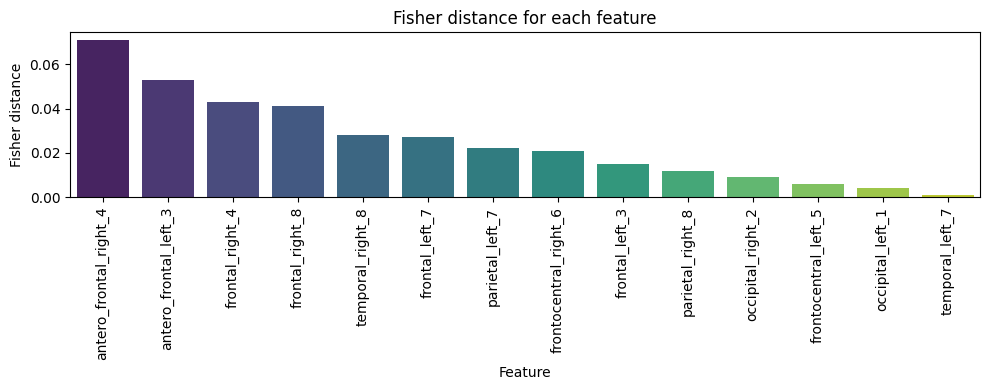

,Feature,Fisher Distance
antero_frontal_right_4,antero_frontal_right_4,0.071
antero_frontal_left_3,antero_frontal_left_3,0.053
frontal_right_4,frontal_right_4,0.043
frontal_right_8,frontal_right_8,0.041
temporal_right_8,temporal_right_8,0.028
frontal_left_7,frontal_left_7,0.027
parietal_left_7,parietal_left_7,0.022
frontocentral_right_6,frontocentral_right_6,0.021
frontal_left_3,frontal_left_3,0.015
parietal_right_8,parietal_right_8,0.012


In [25]:
# Calculate the Fisher distance for each scaled feature
fisher = calculate_fisher_distance(df_scaled.drop(columns=['eye_state']))

fisher_table = pd.DataFrame({
    'Feature': df_scaled.drop(columns=['eye_state']).columns,
    'Fisher Distance': fisher
}).sort_values(by='Fisher Distance', ascending=False)

# Visualise the Fisher distances
plt.figure(figsize=(10, 4))
sns.barplot(x='Feature', y='Fisher Distance', data=fisher_table, palette='viridis')
plt.title('Fisher distance for each feature')
plt.ylabel('Fisher distance')
plt.xlabel('Feature')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Display the table
fisher_table

## 4. Principal Component Analysis (PCA)

PCA is an unsupervised dimensionality reduction technique that transforms the original features into a new set of orthogonal components.
Computation of the principal components and examine their relationship to class separation via Fisher distance and explained variance.

### 4.1 Computing PCA

In [26]:
# Fit PCA on the scaled features
from sklearn.decomposition import PCA

pca = PCA()
data_PCA = pca.fit_transform(df_scaled.drop(columns=['eye_state']))

In [27]:
# Convert the PCA result to a dataframe and retain the original feature names for readability
data_PCA = pd.DataFrame(data_PCA, columns=df_scaled.drop(columns='eye_state').columns)

# Preview the first few principal component scores
data_PCA.head()

,antero_frontal_left_3,frontal_left_7,frontal_left_3,frontocentral_left_5,temporal_left_7,parietal_left_7,occipital_left_1,occipital_right_2,parietal_right_8,temporal_right_8,frontocentral_right_6,frontal_right_4,frontal_right_8,antero_frontal_right_4
0,3.012774,-0.605741,-0.593411,0.549834,1.568448,1.178983,1.367624,1.930951,0.016333,0.662386,0.471938,0.088195,-1.258902,0.141870
1,2.210115,-1.034781,-0.459869,0.846315,1.915335,0.677151,1.653666,1.361367,0.114565,0.752183,0.514007,-0.224348,-1.421820,-0.008957
2,2.039858,-1.707394,-0.277444,1.037205,2.038454,0.479656,1.560272,1.146148,0.491303,0.674040,0.274808,-0.065160,-1.358510,0.097021
3,2.949318,-1.400647,-0.441307,0.753218,1.801715,0.826460,1.329630,1.551927,0.557155,0.335416,0.486400,0.124757,-1.145519,0.271034
4,2.919298,-1.396772,-0.542401,0.630395,1.152717,0.788791,1.246995,1.819157,0.474665,0.056079,0.519863,-0.250503,-0.945078,0.345685


In [28]:
# Compute the Fisher distance for each principal component
fisher_pca = calculate_fisher_distance(data_PCA)

In [29]:
# Assemble a summary dataframe with eigenvalues and Fisher distances for each component
pca_results = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(data_PCA.shape[1])],
    'Eigenvalue (Variance)': pca.explained_variance_,
    'Explained Variance Ratio': pca.explained_variance_ratio_,
    'Fisher Distance': fisher_pca
})

In [30]:
# Display the PCA summary table
pca_results

,Principal Component,Eigenvalue (Variance),Explained Variance Ratio,Fisher Distance
antero_frontal_left_3,PC1,7.376454,0.526854,0.020
frontal_left_7,PC2,2.133651,0.152393,0.006
frontal_left_3,PC3,1.792424,0.128022,0.093
frontocentral_left_5,PC4,0.544294,0.038876,0.007
temporal_left_7,PC5,0.491284,0.035089,0.003
parietal_left_7,PC6,0.356821,0.025486,0.005
occipital_left_1,PC7,0.270278,0.019304,0.002
occipital_right_2,PC8,0.225686,0.016119,0.062
parietal_right_8,PC9,0.209327,0.014951,0.010
temporal_right_8,PC10,0.183599,0.013113,0.000


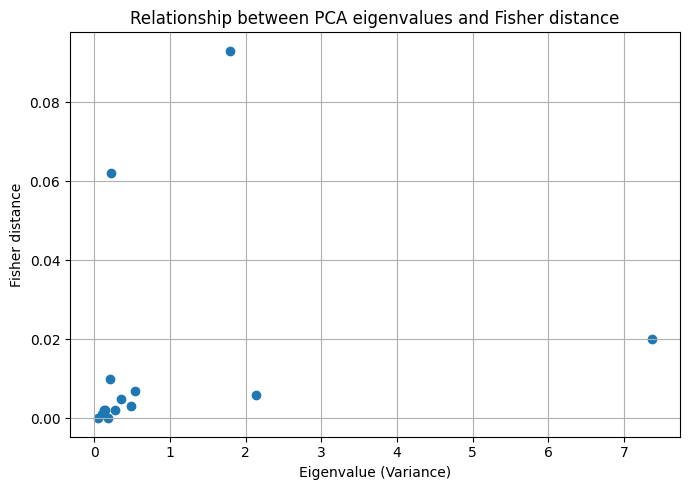

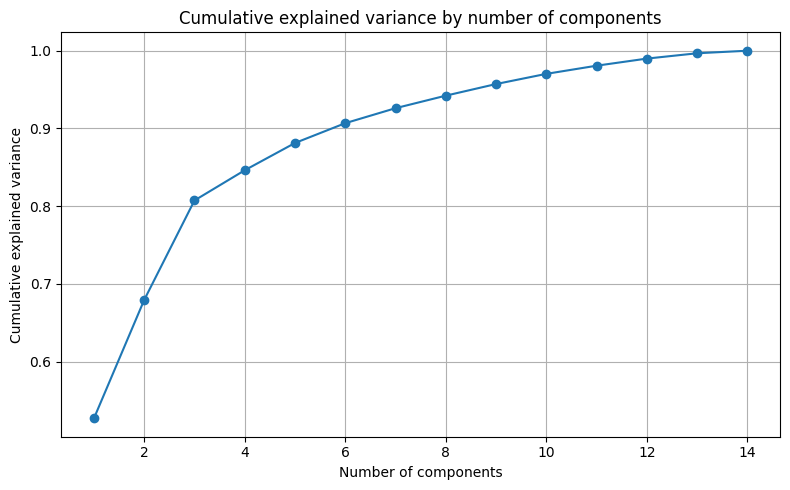

In [31]:
# Explore the relationship between eigenvalues (variance captured) and Fisher distance
plt.figure(figsize=(7,5))
plt.scatter(pca_results['Eigenvalue (Variance)'], pca_results['Fisher Distance'])
plt.xlabel('Eigenvalue (Variance)')
plt.ylabel('Fisher distance')
plt.title('Relationship between PCA eigenvalues and Fisher distance')
plt.grid(True)
plt.tight_layout()
plt.show()

# Additionally plot the cumulative explained variance to determine how many PCs are needed to capture most of the variance
cumulative_variance = np.cumsum(pca_results['Explained Variance Ratio'])
plt.figure(figsize=(8,5))
plt.plot(range(1, len(cumulative_variance)+1), cumulative_variance, marker='o')
plt.title('Cumulative explained variance by number of components')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.grid(True)
plt.tight_layout()
plt.show()

## 5. Visualising Principal Components

Visualise the projections onto the first two principal components (which capture the most variance) and the last two components (which capture the least variance). Colour indicates the eye state.

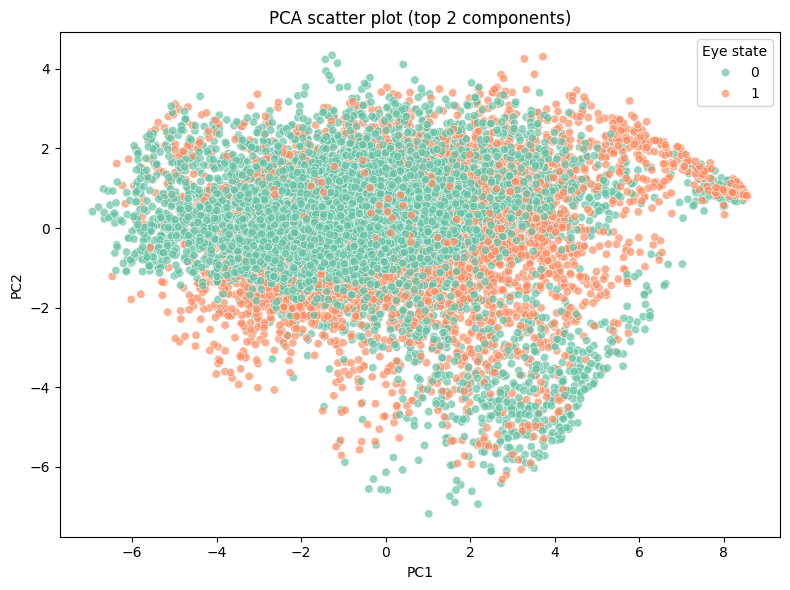

In [32]:
# Scatter plot of the top two principal components
plt.figure(figsize=(8, 6))
sns.scatterplot(x=data_PCA.iloc[:, 0], y=data_PCA.iloc[:, 1], hue=df_scaled['eye_state'], palette='Set2', alpha=0.7)
plt.title('PCA scatter plot (top 2 components)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='Eye state')
plt.tight_layout()
plt.show()

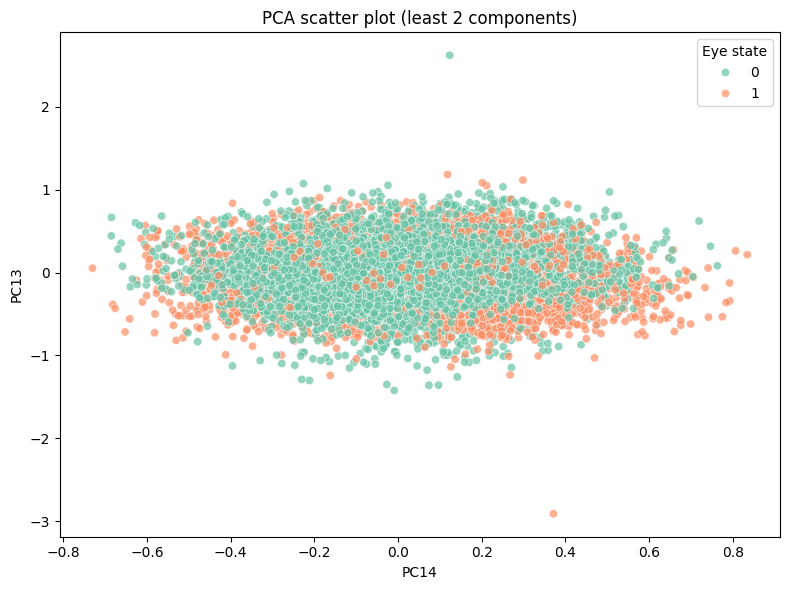

In [33]:
# Scatter plot of the least two principal components
plt.figure(figsize=(8, 6))
sns.scatterplot(x=data_PCA.iloc[:, -1], y=data_PCA.iloc[:, -2], hue=df_scaled['eye_state'], palette='Set2', alpha=0.7)
plt.title('PCA scatter plot (least 2 components)')
plt.xlabel(f'PC{data_PCA.shape[1]}')
plt.ylabel(f'PC{data_PCA.shape[1]-1}')
plt.legend(title='Eye state')
plt.tight_layout()
plt.show()

## 6. Linear Discriminant Analysis (LDA)

LDA is a supervised dimensionality reduction technique. It explicitly maximises class separability. For a binary classification problem it produces one discriminant component.

In [34]:
# Fit an LDA model on the scaled features
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

LDA = LinearDiscriminantAnalysis()
data_LDA = LDA.fit_transform(df_scaled.drop(columns=['eye_state']), df_scaled['eye_state'])

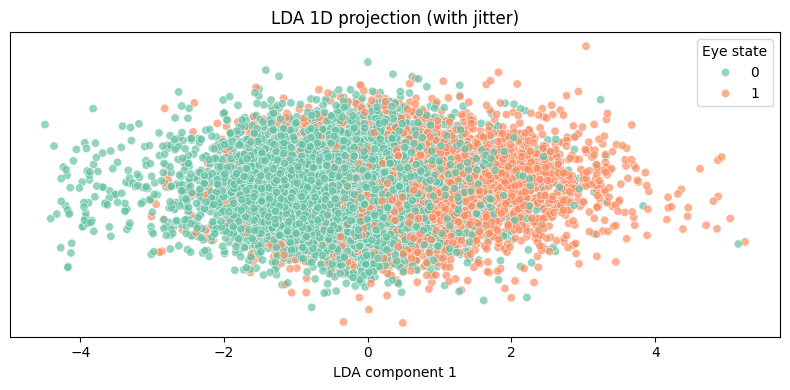

In [35]:
# Scatter plot of the LDA projection (1D) with jitter to avoid overlapping points
y_jitter = np.random.normal(0, 0.02, size=data_LDA.shape[0])
plt.figure(figsize=(8, 4))
sns.scatterplot(x=data_LDA[:, 0], y=y_jitter, hue=df_scaled['eye_state'], palette='Set2', alpha=0.7)
plt.title('LDA 1D projection (with jitter)')
plt.xlabel('LDA component 1')
plt.yticks([])  # Hide y‑axis as it carries no information
plt.legend(title='Eye state')
plt.tight_layout()
plt.show()

In [36]:
# Evaluate class separability using the silhouette score on the PCA and LDA projections
from sklearn.metrics import silhouette_score

pca_score = silhouette_score(data_PCA.iloc[:, :2], df_scaled['eye_state'])
lda_score = silhouette_score(data_LDA, df_scaled['eye_state'])

print('--- Class separability (silhouette) ---')
print(f'PCA (top 2 components) silhouette score: {pca_score:.4f}')
print(f'LDA (1D projection) silhouette score:    {lda_score:.4f}')

--- Class separability (silhouette) ---
PCA (top 2 components) silhouette score: 0.0145
LDA (1D projection) silhouette score:    0.0785


In [37]:
# Compute the Fisher distance on the LDA projection
lda_fisher = calculate_fisher_distance(data_LDA)

In [38]:
# Compare PCA and LDA in terms of Fisher distance and silhouette score
pca_fisher_best = max(fisher_pca)

pca_lda_comp = pd.DataFrame({
    'Metric': ['Best Fisher distance', 'Silhouette score'],
    'PCA (unsupervised)': [pca_fisher_best, pca_score],
    'LDA (supervised)': [lda_fisher[0], lda_score]
})

pca_lda_comp.set_index('Metric', inplace=True)

print('--- PCA vs LDA performance comparison ---')
pca_lda_comp

--- PCA vs LDA performance comparison ---


,PCA (unsupervised),LDA (supervised)
Metric,,
Best Fisher distance,0.093000,0.230000
Silhouette score,0.014459,0.078509


In [39]:
# Extract the first two principal components for clustering
first_2_PCA = data_PCA.iloc[:, :2].copy()

In [40]:
# Preview the first few rows of the two‑dimensional PCA data
first_2_PCA.head()

,antero_frontal_left_3,frontal_left_7
0,3.012774,-0.605741
1,2.210115,-1.034781
2,2.039858,-1.707394
3,2.949318,-1.400647
4,2.919298,-1.396772


## 7. Clustering Analysis

K‑Means, DBSCAN, t‑SNE (for visualisation) and Self‑Organising Maps (SOM).
For K‑Means and DBSCAN operating in the two–dimensional PCA space. For t‑SNE and SOM use the full scaled feature set.

In [41]:
# ---- K‑Means Clustering ----
# Perform K‑Means with 2 clusters on the first two principal components
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

kmeans = KMeans(n_clusters=2, random_state=777, n_init=10)
kmeans_labels = kmeans.fit_predict(first_2_PCA)
centers = kmeans.cluster_centers_

# Evaluate clustering performance against the true labels
kmeans_ari = adjusted_rand_score(df_scaled['eye_state'], kmeans_labels)
kmeans_nmi = normalized_mutual_info_score(df_scaled['eye_state'], kmeans_labels)
kmeans_sil = silhouette_score(first_2_PCA, kmeans_labels)

print(f'K‑Means Adjusted Rand Index (ARI): {kmeans_ari:.4f}')
print(f'K‑Means Normalised Mutual Information (NMI): {kmeans_nmi:.4f}')
print(f'K‑Means Silhouette score: {kmeans_sil:.4f}')

K‑Means Adjusted Rand Index (ARI): 0.0172
K‑Means Normalised Mutual Information (NMI): 0.0086
K‑Means Silhouette score: 0.4511


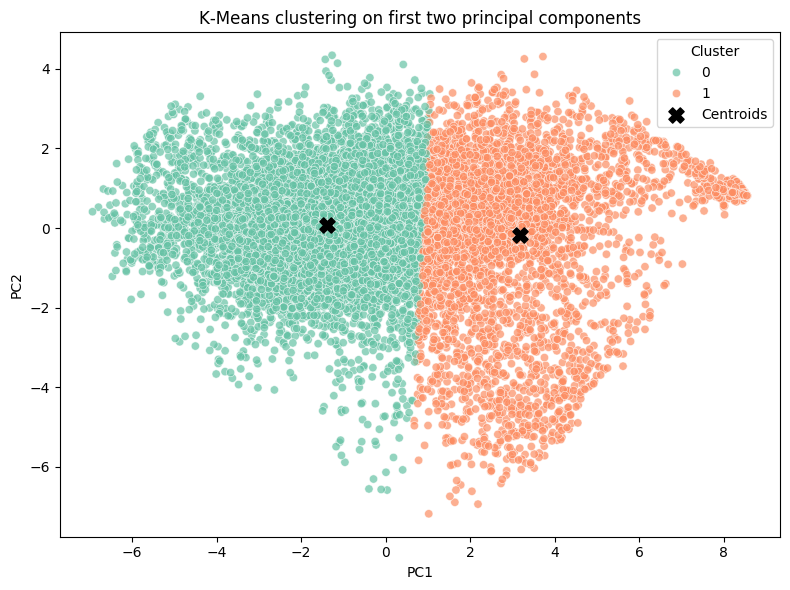

In [42]:
# Visualise the K‑Means clusters and centroids
plt.figure(figsize=(8, 6))
sns.scatterplot(x=first_2_PCA.iloc[:, 0], y=first_2_PCA.iloc[:, 1], hue=kmeans_labels, palette='Set2', alpha=0.7)
plt.scatter(centers[:, 0], centers[:, 1], marker='X', s=120, c='black', label='Centroids')
plt.title('K‑Means clustering on first two principal components')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

DBSCAN Adjusted Rand Index (non‑noise): 0.0026
DBSCAN Normalised Mutual Information (non‑noise): 0.0014
DBSCAN Silhouette score (non‑noise): 0.3377


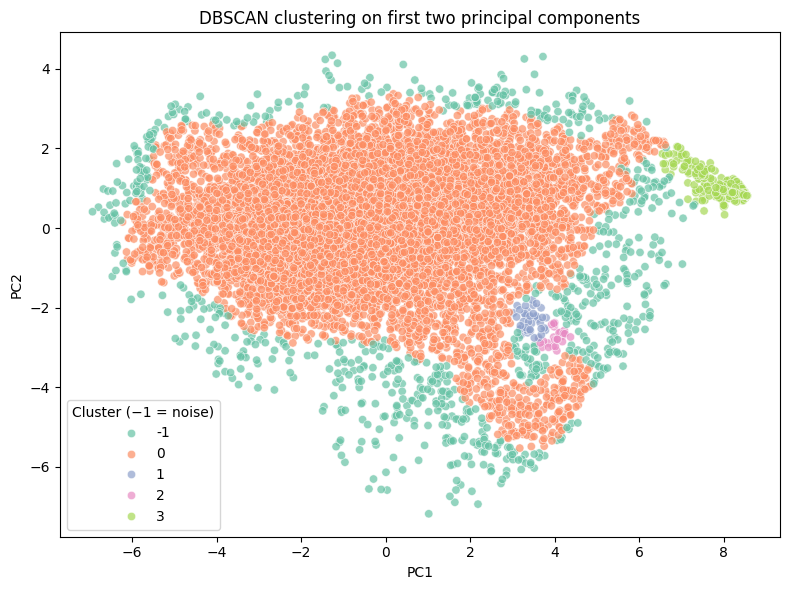

In [43]:
# ---- DBSCAN Clustering ----
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.4, min_samples=30)
db_labels = dbscan.fit_predict(first_2_PCA)

# Evaluate DBSCAN only on non‑noise points (-1 indicates noise)
mask = db_labels != -1
if mask.sum() > 0 and len(np.unique(db_labels[mask])) > 1:
    db_ari = adjusted_rand_score(df_scaled.loc[mask, 'eye_state'], db_labels[mask])
    db_nmi = normalized_mutual_info_score(df_scaled.loc[mask, 'eye_state'], db_labels[mask])
    db_sil = silhouette_score(first_2_PCA.loc[mask], db_labels[mask])
else:
    db_ari = db_nmi = db_sil = np.nan

print(f'DBSCAN Adjusted Rand Index (non‑noise): {db_ari:.4f}')
print(f'DBSCAN Normalised Mutual Information (non‑noise): {db_nmi:.4f}')
print(f'DBSCAN Silhouette score (non‑noise): {db_sil:.4f}')

# Visualise DBSCAN clusters, colouring noise as a separate category
plt.figure(figsize=(8, 6))
sns.scatterplot(x=first_2_PCA.iloc[:, 0], y=first_2_PCA.iloc[:, 1], hue=db_labels, palette='Set2', alpha=0.7)
plt.title('DBSCAN clustering on first two principal components')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='Cluster (−1 = noise)')
plt.tight_layout()
plt.show()

In [44]:
# ---- t‑SNE for visualisation ----
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42)

In [45]:
# Fit t‑SNE on the scaled data (excluding the target)
X_tsne = tsne.fit_transform(df_scaled.drop(columns=['eye_state']))

# Report the KL divergence of the t‑SNE embedding
tsne.kl_divergence_

1.60943603515625

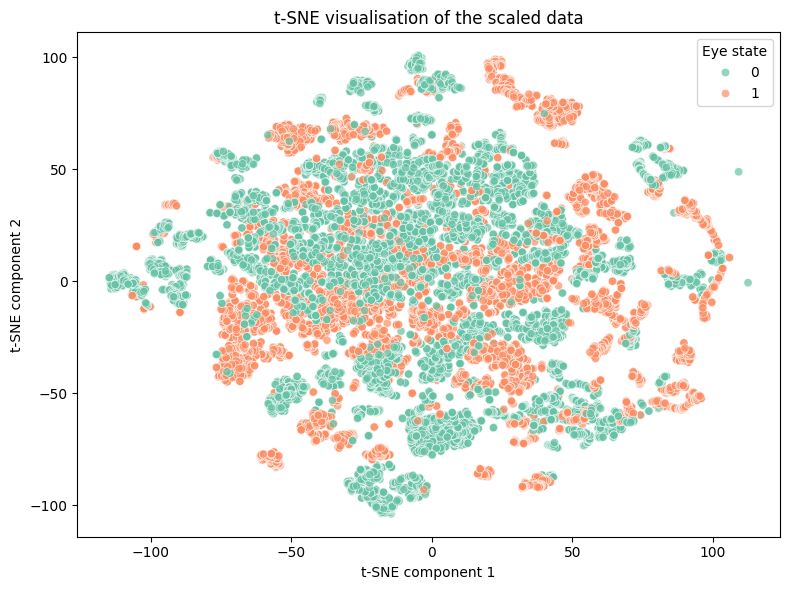

In [46]:
# Visualise the t‑SNE embedding coloured by the true eye state
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=df_scaled['eye_state'], palette='Set2', alpha=0.7)
plt.title('t‑SNE visualisation of the scaled data')
plt.xlabel('t‑SNE component 1')
plt.ylabel('t‑SNE component 2')
plt.legend(title='Eye state')
plt.tight_layout()
plt.show()

In [47]:
# Prepare the input data for the Self‑Organising Map (SOM)
data = df_scaled.drop(columns=['eye_state']).values

In [48]:
# ---- Self‑Organising Map (SOM) ----
from sklearn_som.som import SOM

som = SOM(m=5, n=5, dim=data.shape[1])

In [49]:
# Train the SOM on the scaled data
som.fit(data)

In [50]:
# Obtain the BMU (best matching unit) index for each sample
predictions = som.predict(data)

In [51]:
# Inspect the first few SOM predictions
predictions[:10]

array([16,  5,  0,  0,  0,  5,  5,  5,  0,  0])

In [52]:
# Convert BMU indices into 2D coordinates on the SOM grid
coords = np.array([(p // som.n, p % som.n) for p in predictions])

som_df = pd.DataFrame({
    'SOM_X': coords[:, 0],
    'SOM_Y': coords[:, 1],
    'eye_state': df_scaled['eye_state'].values
})

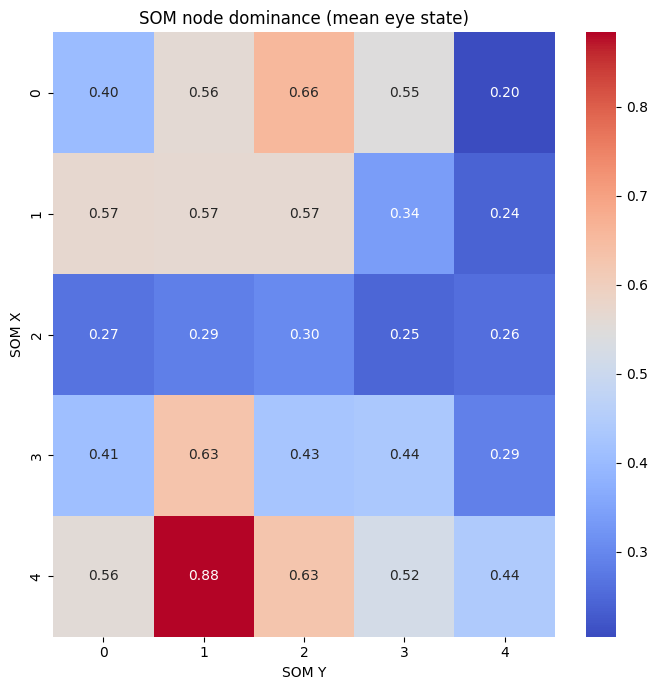

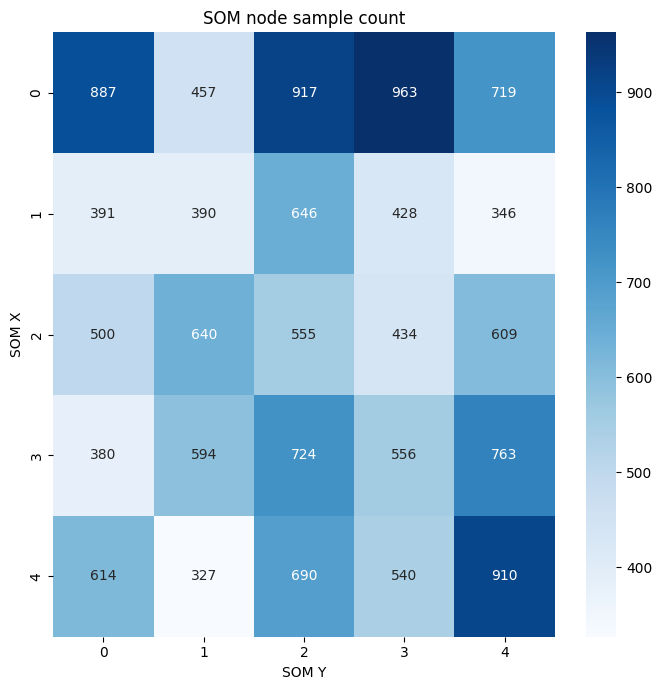

In [53]:
# Compute the average eye_state value in each SOM node
dominance_map = som_df.groupby(['SOM_X', 'SOM_Y'])['eye_state'].mean().reset_index()
heatmap_data = dominance_map.pivot(index='SOM_X', columns='SOM_Y', values='eye_state')

# Plot the dominance heatmap where lower values (closer to 0) indicate class 0 dominance and higher values indicate class 1 dominance
plt.figure(figsize=(7, 7))
sns.heatmap(heatmap_data, annot=True, fmt='.2f', cmap='coolwarm', cbar=True)
plt.title('SOM node dominance (mean eye state)')
plt.xlabel('SOM Y')
plt.ylabel('SOM X')
plt.tight_layout()
plt.show()

# Also compute a heatmap of how many samples fall into each SOM node
count_map = som_df.groupby(['SOM_X', 'SOM_Y']).size().reset_index(name='count')
count_heatmap = count_map.pivot(index='SOM_X', columns='SOM_Y', values='count')
plt.figure(figsize=(7, 7))
sns.heatmap(count_heatmap, annot=True, fmt='d', cmap='Blues')
plt.title('SOM node sample count')
plt.xlabel('SOM Y')
plt.ylabel('SOM X')
plt.tight_layout()
plt.show()

## 8. Hypothesis Testing
the null hypothesis that the mean of a selected feature is equal across the two classes.
Random samples of size 36 and 64 are drawn from each class and a Welch t‑test is applied. Compute Cohen's d effect size to quantify the magnitude of the difference.

In [54]:
# Select the feature to test and significance level
feature = 'antero_frontal_left_3'
alpha = 0.05

# Separate the full cleaned data for the two classes
class0_data = df_cleaned[df_cleaned['eye_state'] == 0][feature]
class1_data = df_cleaned[df_cleaned['eye_state'] == 1][feature]

In [55]:
from scipy.stats import ttest_ind

# Define a function to perform a Welch t‑test on random samples and compute Cohen's d
def perform_ttest(sample_size):
    class0_sample = class0_data.sample(n=sample_size, random_state=42)
    class1_sample = class1_data.sample(n=sample_size, random_state=42)

    t_stat, p_value = ttest_ind(class0_sample, class1_sample, equal_var=False)

    # Compute pooled standard deviation for Cohen's d
    pooled_std = np.sqrt(((sample_size - 1) * class0_sample.var() + (sample_size - 1) * class1_sample.var()) / (2 * sample_size - 2))
    cohen_d = (class0_sample.mean() - class1_sample.mean()) / pooled_std

    print('Sample size from each class:', sample_size)
    print('Feature:', feature)
    print('Class 0 mean:', class0_sample.mean())
    print('Class 1 mean:', class1_sample.mean())
    print('t‑statistic:', t_stat)
    print('p‑value:', p_value)
    print("Cohen's d:", cohen_d)

    if p_value < alpha:
        print('Result: Reject H0')
        print('Interpretation: There is a statistically significant difference between class means.')
    else:
        print('Result: Fail to reject H0')
        print('Interpretation: There is no statistically significant difference between class means.')

In [56]:
# T-test with 36 samples from each class
perform_ttest(36)

Sample size from each class: 36
Feature: antero_frontal_left_3
Class 0 mean: 4292.334722222222
Class 1 mean: 4314.444166666666
t‑statistic: -3.3016756608561506
p‑value: 0.001518369630740459
Cohen's d: -0.7782124163566532
Result: Reject H0
Interpretation: There is a statistically significant difference between class means.


In [57]:
# T-test with 64 samples from each class
perform_ttest(64)

Sample size from each class: 64
Feature: antero_frontal_left_3
Class 0 mean: 4295.6079687500005
Class 1 mean: 4305.400625
t‑statistic: -1.905531475699456
p‑value: 0.05899115833728268
Cohen's d: -0.3368535570578735
Result: Fail to reject H0
Interpretation: There is no statistically significant difference between class means.


In [58]:
# Full data Welch t‑test and effect size
from scipy.stats import ttest_ind

# Perform Welch's t‑test on the full cleaned data for the selected feature
t_stat_full, p_value_full = ttest_ind(class0_data, class1_data, equal_var=False)

# Compute pooled standard deviation for the full data
pooled_std_full = np.sqrt(((len(class0_data) - 1) * class0_data.var() + (len(class1_data) - 1) * class1_data.var()) / (len(class0_data) + len(class1_data) - 2))
cohen_d_full = (class0_data.mean() - class1_data.mean()) / pooled_std_full

print('--- Full data t‑test ---')
print('t‑statistic:', t_stat_full)
print('p‑value:', p_value_full)
print("Cohen's d:", cohen_d_full)


--- Full data t‑test ---
t‑statistic: -19.874474476553093
p‑value: 9.582990033719909e-87
Cohen's d: -0.32546856375556427
